100%|██████████| 170M/170M [01:04<00:00, 2.65MB/s]


Epoch: 1 Loss: 2.0052 Accuracy: 27.4 %
Epoch: 2 Loss: 1.6423 Accuracy: 41.24 %
Epoch: 3 Loss: 1.4911 Accuracy: 46.7 %
Epoch: 4 Loss: 1.364 Accuracy: 52.12 %
Epoch: 5 Loss: 1.3055 Accuracy: 53.12 %
Test Accuracy: 48.3 %


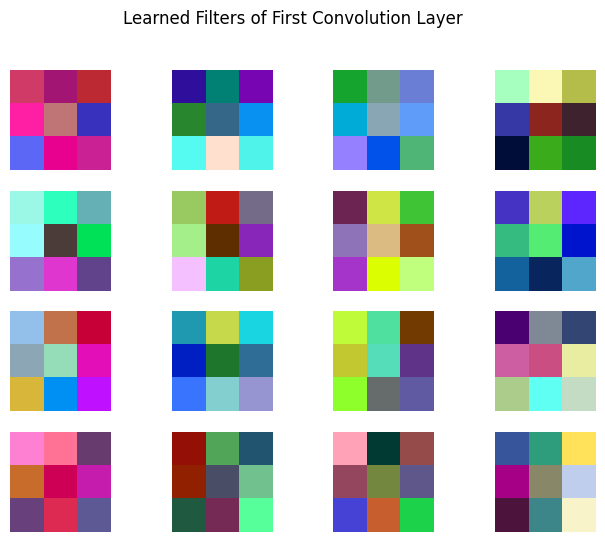

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])
trainset = torchvision.datasets.CIFAR10(
      root="./data",
      train=True,
      download=True,
      transform=transform
)
testset = torchvision.datasets.CIFAR10(
      root="./data",
      train=False,
      download=True,
      transform=transform
)
trainset = torch.utils.data.Subset(trainset, range(5000))
testset = torch.utils.data.Subset(testset, range(1000))

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True
)
testloader = torch.utils.data.DataLoader(
      testset,
      batch_size=64,
      shuffle=False
)
class CNN(nn.Module):
      def __init__(self):
          super(CNN,self).__init__()

          self.conv1 = nn.Conv2d(3,16,3,padding=1)
          self.conv2 = nn.Conv2d(16,32,3,padding=1)

          self.pool = nn.MaxPool2d(2,2)

          self.fc1 = nn.Linear(32*8*8,64)
          self.fc2 = nn.Linear(64,10)
      def forward(self,x):
          x = torch.relu(self.conv1(x))
          x = self.pool(x)

          x = torch.relu(self.conv2(x))
          x = self.pool(x)

          x = x.view(x.size(0),-1)

          x = torch.relu(self.fc1(x))
          x = self.fc2(x)

          return x
model = CNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr=0.001)

for epoch in range(5):
    model.train()
    correct = 0
    total = 0
    loss_total = 0

    for images,labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        loss_total += loss.item()
        _,predicted = torch.max(outputs,1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    accuracy = 100 * correct / total

    print(
        "Epoch:",epoch+1,
        "Loss:",round(loss_total/len(trainloader),4),
        "Accuracy:",round(accuracy,2),"%"
    )
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images,labels in testloader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _,predicted = torch.max(outputs,1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
accuracy = 100 * correct / total

print("Test Accuracy:",round(accuracy,2),"%")

filters = model.conv1.weight.data.cpu()

plt.figure(figsize=(8,6))

for i in range(16):
    plt.subplot(4,4,i+1)
    f = filters[i]
    f = (f - f.min()) / (f.max() - f.min())
    plt.imshow(f.permute(1,2,0))
    plt.axis("off")
plt.suptitle("Learned Filters of First Convolution Layer")
plt.show()